<a href="https://colab.research.google.com/github/Bussy11/Ai_Payroll_Anomally_Detection/blob/main/Payroll_system.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [15]:

# CELL 1: IMPORT REQUIRED LIBRARIES

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import io
import re

from sklearn.ensemble import IsolationForest
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA

from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    accuracy_score
)

print("All libraries imported successfully!")

All libraries imported successfully!


In [12]:
# ==========================================
# CELL 2: WELCOME AND LOAD DATASET
# ==========================================

print("=" * 50)
print("WELCOME TO AI-PAYROLL ANOMALY DETECTION SYSTEM")
print("=" * 50)

user_name = input("Enter your name: ")
user_state = input("Enter your state: ")
user_lg = input("Enter your Local Government Area: ")

print("\nWelcome,", user_name)
print("State:", user_state)
print("Local Government:", user_lg)

print("\nChoose your dataset:")
print("1. Upload an existing CSV file")
print("2. Generate sample payroll data")

choice = input("Enter 1 or 2: ").strip()

if choice == "1":
    print("\nSelect your CSV file.")
    uploaded = files.upload()

    csv_files = [
        filename for filename in uploaded
        if filename.lower().endswith(".csv")
    ]

    if not csv_files:
        raise ValueError(
            "No CSV file uploaded. Please upload a .csv file."
        )

    filename = csv_files[0]

    df = pd.read_csv(
        io.BytesIO(uploaded[filename]),
        encoding="utf-8-sig"
    )

    print("\nCSV file uploaded successfully:", filename)

elif choice == "2":

    np.random.seed(42)

    number_of_employees = 200

    basic_salary = np.random.randint(
        60000, 250001, number_of_employees
    )

    allowance = np.random.randint(
        10000, 50001, number_of_employees
    )

    deduction = np.random.randint(
        2000, 20001, number_of_employees
    )

    df = pd.DataFrame({
        "Employee_ID": [
            f"EMP{i:04d}"
            for i in range(1, number_of_employees + 1)
        ],
        "Name": [
            f"Employee_{i}"
            for i in range(1, number_of_employees + 1)
        ],
        "State": ["Kogi"] * number_of_employees,
        "LG": ["Sample_LGA"] * number_of_employees,
        "Basic_Salary": basic_salary,
        "Allowance": allowance,
        "Deduction": deduction,
        "Age": np.random.randint(
            22, 61, number_of_employees
        )
    })

    df["Net_Salary"] = (
        df["Basic_Salary"]
        + df["Allowance"]
        - df["Deduction"]
    )

    # Introduce artificial anomalies for demonstration.
    df.loc[5, "Net_Salary"] = 1500000
    df.loc[15, "Basic_Salary"] = 950000
    df.loc[25, "Allowance"] = 450000

    print("\nSample payroll dataset generated successfully.")

else:
    raise ValueError(
        "Invalid choice. Run Cell 2 again and enter 1 or 2."
    )

print("\nDataset loaded successfully!")
print("Number of rows:", len(df))
print("Number of columns:", len(df.columns))

display(df.head())

WELCOME TO AI-PAYROLL ANOMALY DETECTION SYSTEM
Enter your name: Ampitan OLUWABUSAYO 
Enter your state: Kogi state 
Enter your Local Government Area: Yagba East 

Welcome, Ampitan OLUWABUSAYO 
State: Kogi state 
Local Government: Yagba East 

Choose your dataset:
1. Upload an existing CSV file
2. Generate sample payroll data
Enter 1 or 2: 1

Select your CSV file.


Saving kogi_state_lg_payroll-2.csv to kogi_state_lg_payroll-2.csv

CSV file uploaded successfully: kogi_state_lg_payroll-2.csv

Dataset loaded successfully!
Number of rows: 1200
Number of columns: 9


,staff_id,lga,grade_level,age,days_present,overtime_hours,basic_salary,allowances,bank_account
0,KG200000,Bassa,15,47,20,6,155645.59,51022.33,9597492782
1,KG200001,Ofu,7,49,20,1,85950.28,30857.37,8865326770
2,KG200002,Kabba/Bunu,5,49,19,2,65147.51,25732.26,3769501980
3,KG200003,Igalamela-Odolu,7,27,22,7,86739.36,26978.87,9375625448
4,KG200004,Idah,10,30,22,7,112460.56,40221.54,2205860211


In [16]:
# ==========================================
# CELL 3: STANDARDIZE COLUMN NAMES
# ==========================================

df.columns = [
    re.sub(
        r"_+",
        "_",
        re.sub(
            r"[^a-zA-Z0-9]+",
            "_",
            str(column).strip()
        )
    ).strip("_")
    for column in df.columns
]

# Standardize common column-name variations.
column_aliases = {
    "employee_id": "Employee_ID",
    "employeeid": "Employee_ID",
    "staff_id": "Employee_ID",
    "staff_no": "Employee_ID",
    "employee_name": "Name",
    "full_name": "Name",
    "name": "Name",
    "state": "State",
    "lg": "LG",
    "lga": "LG",
    "local_government": "LG",
    "local_government_area": "LG",
    "basic_salary": "Basic_Salary",
    "basic_pay": "Basic_Salary",
    "allowances": "Allowance",
    "allowance": "Allowance",
    "deductions": "Deduction",
    "deduction": "Deduction",
    "net_pay": "Net_Salary",
    "net_salary": "Net_Salary",
    "salary": "Net_Salary",
    "age": "Age"
}

rename_columns = {}

for column in df.columns:
    key = column.lower()

    if key in column_aliases:
        rename_columns[column] = column_aliases[key]

df = df.rename(columns=rename_columns)

# Remove accidental duplicate column names.
df = df.loc[:, ~df.columns.duplicated()].copy()

print("Column names standardized successfully.")
print("\nAvailable columns:")
print(df.columns.tolist())

display(df.head())

Column names standardized successfully.

Available columns:
['Employee_ID', 'LG', 'grade_level', 'Age', 'days_present', 'overtime_hours', 'Basic_Salary', 'Allowance', 'bank_account']


,Employee_ID,LG,grade_level,Age,days_present,overtime_hours,Basic_Salary,Allowance,bank_account
0,KG200000,Bassa,15,47,20,6,155645.59,51022.33,9597492782
1,KG200001,Ofu,7,49,20,1,85950.28,30857.37,8865326770
2,KG200002,Kabba/Bunu,5,49,19,2,65147.51,25732.26,3769501980
3,KG200003,Igalamela-Odolu,7,27,22,7,86739.36,26978.87,9375625448
4,KG200004,Idah,10,30,22,7,112460.56,40221.54,2205860211


In [17]:
# ==========================================
# CELL 4: CLEAN AND VALIDATE THE DATASET
# ==========================================

print("=" * 50)
print("DATA CLEANING STARTED")
print("=" * 50)

# Work on a copy to preserve the original dataset.
df = df.copy()

# Remove completely empty rows and columns.
df = df.dropna(how="all")
df = df.dropna(axis=1, how="all")

# Remove leading and trailing spaces from text.
for column in df.select_dtypes(include=["object"]).columns:
    df[column] = df[column].map(
        lambda value: value.strip()
        if isinstance(value, str)
        else value
    )

# Identify columns that contain payroll amounts.
salary_columns = [
    column for column in [
        "Basic_Salary",
        "Allowance",
        "Deduction",
        "Net_Salary"
    ]
    if column in df.columns
]

# Convert salary columns to numbers.
for column in salary_columns:

    if df[column].dtype == "object":

        df[column] = df[column].astype(str).str.replace(
            r"[\s,₦]",
            "",
            regex=True
        )

        df[column] = df[column].replace(
            {
                "": np.nan,
                "nan": np.nan,
                "None": np.nan,
                "N/A": np.nan,
                "NA": np.nan,
                "-": np.nan
            }
        )

    df[column] = pd.to_numeric(
        df[column],
        errors="coerce"
    )

# Convert Age to numeric where available.
if "Age" in df.columns:
    df["Age"] = pd.to_numeric(
        df["Age"],
        errors="coerce"
    )

# Report missing values before handling them.
print("\nMissing values before cleaning:")
display(df.isnull().sum().to_frame("Missing_Values"))

# Remove fully duplicated rows.
duplicate_count = int(df.duplicated().sum())

df = df.drop_duplicates().copy()

print("\nCompletely duplicated rows removed:", duplicate_count)

# Fill missing numerical values with the column median.
for column in df.select_dtypes(include=["number"]).columns:

    if df[column].isnull().any():

        median_value = df[column].median()

        if pd.notna(median_value):
            df[column] = df[column].fillna(median_value)

# Fill missing text values with an explicit label.
for column in df.select_dtypes(include=["object"]).columns:

    df[column] = df[column].replace("", np.nan)

    df[column] = df[column].fillna("Unknown")

# Recalculate Net_Salary when all three components exist.
if all(
    column in df.columns
    for column in [
        "Basic_Salary",
        "Allowance",
        "Deduction"
    ]
):
    calculated_net = (
        df["Basic_Salary"]
        + df["Allowance"]
        - df["Deduction"]
    )

    if "Net_Salary" not in df.columns:
        df["Net_Salary"] = calculated_net

    else:
        invalid_net = (
            df["Net_Salary"].isna()
            | ~np.isclose(
                df["Net_Salary"],
                calculated_net,
                equal_nan=False
            )
        )

        df.loc[invalid_net, "Net_Salary"] = (
            calculated_net[invalid_net]
        )

# Report negative payroll values for investigation.
for column in salary_columns:

    if column in df.columns:

        negative_count = int(
            (df[column] < 0).sum()
        )

        if negative_count > 0:
            print(
                f"Warning: {negative_count} negative values "
                f"found in {column}."
            )

print("\nMissing values after cleaning:")
display(df.isnull().sum().to_frame("Missing_Values"))

print("\nDATA CLEANING COMPLETED")
print("Rows remaining:", len(df))
print("Columns available:", df.columns.tolist())

display(df.head())

DATA CLEANING STARTED

Missing values before cleaning:


,Missing_Values
Employee_ID,0
LG,0
grade_level,0
Age,0
days_present,0
overtime_hours,0
Basic_Salary,0
Allowance,0
bank_account,0



Completely duplicated rows removed: 0

Missing values after cleaning:


,Missing_Values
Employee_ID,0
LG,0
grade_level,0
Age,0
days_present,0
overtime_hours,0
Basic_Salary,0
Allowance,0
bank_account,0



DATA CLEANING COMPLETED
Rows remaining: 1200
Columns available: ['Employee_ID', 'LG', 'grade_level', 'Age', 'days_present', 'overtime_hours', 'Basic_Salary', 'Allowance', 'bank_account']


,Employee_ID,LG,grade_level,Age,days_present,overtime_hours,Basic_Salary,Allowance,bank_account
0,KG200000,Bassa,15,47,20,6,155645.59,51022.33,9597492782
1,KG200001,Ofu,7,49,20,1,85950.28,30857.37,8865326770
2,KG200002,Kabba/Bunu,5,49,19,2,65147.51,25732.26,3769501980
3,KG200003,Igalamela-Odolu,7,27,22,7,86739.36,26978.87,9375625448
4,KG200004,Idah,10,30,22,7,112460.56,40221.54,2205860211


In [18]:
# ==========================================
# CELL 5: SELECT MACHINE LEARNING FEATURES
# ==========================================

preferred_features = [
    "Basic_Salary",
    "Allowance",
    "Deduction",
    "Net_Salary",
    "Age"
]

features = [
    column for column in preferred_features
    if column in df.columns
    and pd.api.types.is_numeric_dtype(df[column])
]

if len(features) < 2:
    raise ValueError(
        "The dataset needs at least two usable numerical "
        "features. Check the salary columns in your CSV."
    )

X = df[features].copy()

# Remove rows with infinite or missing feature values.
X = X.replace([np.inf, -np.inf], np.nan)

valid_rows = X.notna().all(axis=1)

df = df.loc[valid_rows].copy()
X = X.loc[valid_rows].copy()

if len(X) < 5:
    raise ValueError(
        "At least five usable payroll records are needed."
    )

print("Features selected:")
print(features)

print("\nData ready for machine learning.")
display(X.head())

Features selected:
['Basic_Salary', 'Allowance', 'Age']

Data ready for machine learning.


,Basic_Salary,Allowance,Age
0,155645.59,51022.33,47
1,85950.28,30857.37,49
2,65147.51,25732.26,49
3,86739.36,26978.87,27
4,112460.56,40221.54,30


In [19]:
# ==========================================
# CELL 6: TRAIN ISOLATION FOREST MODEL
# ==========================================

scaler = StandardScaler()

X_scaled = scaler.fit_transform(X)

model = IsolationForest(
    n_estimators=100,
    contamination=0.05,
    random_state=42
)

model.fit(X_scaled)

print("Isolation Forest model trained successfully!")
print("Algorithm: Isolation Forest")
print("Features used:", features)

Isolation Forest model trained successfully!
Algorithm: Isolation Forest
Features used: ['Basic_Salary', 'Allowance', 'Age']


In [20]:
# ==========================================
# CELL 7: DETECT PAYROLL ANOMALIES
# ==========================================

df["Anomaly_Score"] = model.decision_function(
    X_scaled
)

df["Anomaly_Prediction"] = model.predict(
    X_scaled
)

df["Payroll_Status"] = df[
    "Anomaly_Prediction"
].map({
    1: "Normal",
    -1: "Flagged for Review"
})

print("=" * 50)
print("PAYROLL ANOMALY DETECTION RESULTS")
print("=" * 50)

anomalies = df[
    df["Anomaly_Prediction"] == -1
].copy()

normal_records = df[
    df["Anomaly_Prediction"] == 1
].copy()

print("Total payroll records:", len(df))
print("Normal records:", len(normal_records))
print("Records flagged for review:", len(anomalies))

display(
    anomalies.sort_values(
        "Anomaly_Score"
    )
)

if anomalies.empty:
    print("No anomalies were flagged in this dataset.")

PAYROLL ANOMALY DETECTION RESULTS
Total payroll records: 1200
Normal records: 1140
Records flagged for review: 60


,Employee_ID,LG,grade_level,Age,days_present,overtime_hours,Basic_Salary,Allowance,bank_account,Anomaly_Score,Anomaly_Prediction,Payroll_Status
879,KG200879,Kabba/Bunu,13,56,22,14,141511.90,195065.85,9424546881,-0.167875,-1,Flagged for Review
493,KG200493,Ogori/Magongo,15,48,18,9,160265.44,182287.40,4179311255,-0.165742,-1,Flagged for Review
156,KG200156,Okene,11,57,19,5,118314.26,174517.97,2660102924,-0.156675,-1,Flagged for Review
710,KG200710,Ajaokuta,14,52,20,1,432854.82,47341.84,8358682950,-0.156449,-1,Flagged for Review
331,KG200331,Olamaboro,15,44,19,4,156832.84,158448.96,7126059587,-0.154575,-1,Flagged for Review
217,KG200217,Omala,14,39,18,5,410351.02,47107.11,2912617532,-0.153671,-1,Flagged for Review
36,KG200036,Lokoja,15,24,20,13,157717.69,154770.92,7090474317,-0.152776,-1,Flagged for Review
506,KG200506,Igalamela-Odolu,13,46,19,12,138894.49,184904.59,8342379609,-0.147187,-1,Flagged for Review
894,KG200894,Okehi,10,23,20,11,114733.64,151240.45,6167127427,-0.144778,-1,Flagged for Review
1146,KG201146,Kabba/Bunu,12,31,21,2,356156.48,37179.85,9898149478,-0.142488,-1,Flagged for Review


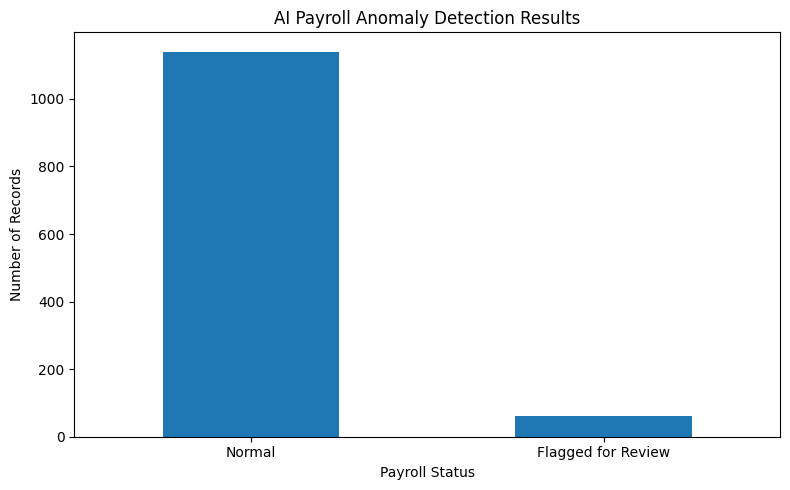

In [23]:
# ==========================================
# CELL 8: VISUALIZE PAYROLL RESULTS
# ==========================================

status_counts = df["Payroll_Status"].value_counts()

status_counts.plot(
    kind="bar",
    figsize=(8, 5)
)

plt.title("AI Payroll Anomaly Detection Results")
plt.xlabel("Payroll Status")
plt.ylabel("Number of Records")
plt.xticks(rotation=0)

plt.tight_layout()
plt.show()

In [26]:
# ==========================================
# CELL 9: GENERATE AND DOWNLOAD REPORT
# ==========================================

import os
import pandas as pd
from google.colab import files
from IPython.display import display

print("=" * 50)
print("GENERATING PAYROLL ANOMALY REPORT")
print("=" * 50)

# Check that the analysis results exist.
if "df" not in globals():
    raise ValueError(
        "Dataset not found. Run Cells 1-8 first."
    )

# Create a copy of the results.
report = df.copy()

# Create a report filename.
output_file = "/content/AI_Payroll_Anomaly_Report.csv"

# Save the report.
report.to_csv(
    output_file,
    index=False,
    encoding="utf-8-sig"
)

# Confirm that the file was created.
if os.path.exists(output_file):

    print("\nREPORT GENERATED SUCCESSFULLY!")
    print("Total records:", len(report))
    print("Report size:", os.path.getsize(output_file), "bytes")
    print("Filename: AI_Payroll_Anomaly_Report.csv")

    print("\nPreparing your download...")

    # Trigger immediate download.
    files.download(output_file)

else:
    raise FileNotFoundError(
        "The report could not be created."
    )

GENERATING PAYROLL ANOMALY REPORT

REPORT GENERATED SUCCESSFULLY!
Total records: 1200
Report size: 104130 bytes
Filename: AI_Payroll_Anomaly_Report.csv

Preparing your download...


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [25]:

from IPython.display import display, FileLink
import os

file_path = "/content/AI_Payroll_Anomaly_Report.csv"

if not os.path.exists(file_path):
    if "df" in globals():
        df.to_csv(file_path, index=False, encoding="utf-8-sig")
    else:
        raise ValueError("Run your payroll analysis first.")

display(FileLink(file_path))

/content/AI_Payroll_Anomaly_Report.csv